In [1]:

import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nTarget distribution:")
display(df["Outcome"].value_counts())



Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing values:


,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Target distribution:


,count
Outcome,
0,500
1,268


In [3]:

# Task 2: Data Preprocessing

# 1. Check dataset dimensions
print("Dataset shape:", df.shape)

# 2. Check column names
print("\nColumns:")
print(df.columns.tolist())

# 3. Check data types and non-null counts
print("\nDataset information:")
df.info()

# 4. Check missing values
print("\nMissing values:")
display(df.isnull().sum())

# 5. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 6. Check target distribution
print("\nOutcome distribution:")
display(df["Outcome"].value_counts())


Dataset shape: (768, 9)

Columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing values:


,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Duplicate rows: 0

Outcome distribution:


,count
Outcome,
0,500
1,268


In [4]:

# Create a copy so the original dataset remains unchanged
df_clean = df.copy()

# Columns where zero commonly represents a missing measurement
invalid_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Replace invalid zeros with NaN
df_clean[invalid_columns] = df_clean[invalid_columns].replace(0, np.nan)

print("Missing values after handling invalid zeros:")
display(df_clean.isnull().sum())


Missing values after handling invalid zeros:


,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [5]:

# Input features
X = df_clean.drop(columns=["Outcome"])

# Target variable
y = df_clean["Outcome"]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())


Feature matrix shape: (768, 8)
Target vector shape: (768,)

Input features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [6]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 614
Testing samples: 154


In [7]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Preprocessing pipeline
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [8]:

%pip -q install scikeras


In [9]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scikeras.wrappers import KerasClassifier

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import numpy as np
import random

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
Libraries imported successfully!


In [10]:

def build_model(
    meta,
    learning_rate=0.001,
    initializer="glorot_uniform",
    activation="relu",
    dropout_rate=0.0,
    neurons=16
):
    n_features = meta["n_features_in_"]

    model = keras.Sequential([
        keras.Input(shape=(n_features,)),

        layers.Dense(
            neurons,
            activation=activation,
            kernel_initializer=initializer
        ),

        layers.Dropout(dropout_rate),

        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

print("Neural network function defined successfully!")


Neural network function defined successfully!


In [11]:

nn_classifier = KerasClassifier(
    model=build_model,
    verbose=0,
    random_state=SEED
)

pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("nn", nn_classifier)
])

print("Complete preprocessing and neural network pipeline created!")


Complete preprocessing and neural network pipeline created!


In [12]:

param_grid = {
    "nn__batch_size": [16, 32],
    "nn__epochs": [50, 100],
    "nn__model__learning_rate": [0.001, 0.01],
    "nn__model__initializer": [
        "glorot_uniform",
        "he_normal"
    ],
    "nn__model__activation": ["relu", "tanh"],
    "nn__model__dropout_rate": [0.0, 0.2],
    "nn__model__neurons": [16, 32]
}

total_combinations = np.prod([
    len(values) for values in param_grid.values()
])

print("Total parameter combinations:", total_combinations)
print("With 3-fold CV, expected model fits:", total_combinations * 3)


Total parameter combinations: 128
With 3-fold CV, expected model fits: 384


In [15]:

%pip install -q --upgrade scikit-learn scikeras




In [17]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=1,
    refit=True,
    verbose=1,
    return_train_score=True,
    error_score="raise"
)

print("Grid Search configured successfully!")


Grid Search configured successfully!


In [22]:

from keras.wrappers import SKLearnClassifier
from sklearn.base import is_classifier

print("Keras Scikit-learn wrapper imported successfully.")


Keras Scikit-learn wrapper imported successfully.


In [23]:

test_estimator = SKLearnClassifier(
    model=build_model
)

print("Is recognized as a classifier:", is_classifier(test_estimator))


Is recognized as a classifier: True


In [24]:
from keras import Sequential, layers
from keras.wrappers import SKLearnClassifier
from sklearn.base import is_classifier

def build_model_for_sklearn(X, y, learning_rate=0.001,
                            initializer="glorot_uniform",
                            activation="relu",
                            dropout_rate=0.0,
                            neurons=16):

    n_features = X.shape[1]

    model = Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(
            neurons,
            activation=activation,
            kernel_initializer=initializer
        ),
        layers.Dropout(dropout_rate),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

print("Model-building function created successfully.")

Model-building function created successfully.


In [25]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report
from keras.wrappers import SKLearnClassifier

# Create the Keras classifier
nn_classifier = SKLearnClassifier(
    model=build_model_for_sklearn,
    model_kwargs={
        "learning_rate": 0.001,
        "initializer": "glorot_uniform",
        "activation": "relu",
        "dropout_rate": 0.0,
        "neurons": 16
    },
    fit_kwargs={"epochs": 50, "batch_size": 32, "verbose": 0}
)

# Connect preprocessing and model
pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("nn", nn_classifier)
])

print("Pipeline created successfully!")

Pipeline created successfully!


In [26]:
param_grid = {
    "nn__model_kwargs": [
        {
            "learning_rate": lr,
            "initializer": init,
            "activation": act,
            "dropout_rate": drop,
            "neurons": neurons
        }
        for lr in [0.001, 0.01]
        for init in ["glorot_uniform", "he_normal"]
        for act in ["relu", "tanh"]
        for drop in [0.0, 0.2]
        for neurons in [16, 32]
    ],
    "nn__fit_kwargs": [
        {"epochs": epochs, "batch_size": batch, "verbose": 0}
        for epochs in [50, 100]
        for batch in [16, 32]
    ]
}

print("Number of model configurations:", len(param_grid["nn__model_kwargs"]))
print("Number of training configurations:", len(param_grid["nn__fit_kwargs"]))


Number of model configurations: 32
Number of training configurations: 4


In [28]:

import numpy as np
from keras import Sequential, layers
from keras.wrappers import SKLearnClassifier

def build_model_for_sklearn(X, y, learning_rate=0.001,
                            initializer="glorot_uniform",
                            activation="relu",
                            dropout_rate=0.0,
                            neurons=16):

    n_features = X.shape[1]

    model = Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(neurons, activation=activation,
                     kernel_initializer=initializer),
        layers.Dropout(dropout_rate),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


In [29]:

y_train = np.asarray(y_train)

if y_train.ndim == 2 and y_train.shape[1] == 2:
    y_train = np.argmax(y_train, axis=1)

y_train = y_train.reshape(-1)

y_test = np.asarray(y_test)
if y_test.ndim == 2 and y_test.shape[1] == 2:
    y_test = np.argmax(y_test, axis=1)

y_test = y_test.reshape(-1)

print("Training labels shape:", y_train.shape)
print("Test labels shape:", y_test.shape)
print("Unique training labels:", np.unique(y_train))


Training labels shape: (614,)
Test labels shape: (154,)
Unique training labels: [0 1]


In [33]:

import numpy as np
import keras
from keras import Sequential, layers
from keras.wrappers import SKLearnClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report

# 1. Convert labels to one-dimensional class IDs
def to_class_ids(y):
    y = np.asarray(y)
    if y.ndim == 2 and y.shape[1] == 2:
        y = np.argmax(y, axis=1)
    return y.reshape(-1).astype(int)

y_train = to_class_ids(y_train)
y_test = to_class_ids(y_test)

# 2. Build a model with TWO output classes
def build_model_for_sklearn(
    X, y, learning_rate=0.001,
    initializer="glorot_uniform", activation="relu",
    dropout_rate=0.0, neurons=16
):
    model = Sequential([
        layers.Input(shape=(X.shape[1],)),
        layers.Dense(
            neurons,
            activation=activation,
            kernel_initializer=initializer
        ),
        layers.Dropout(dropout_rate),
        layers.Dense(2, activation="softmax")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# 3. Recreate classifier and pipeline
nn_classifier = SKLearnClassifier(
    model=build_model_for_sklearn,
    model_kwargs={
        "learning_rate": 0.001,
        "initializer": "glorot_uniform",
        "activation": "relu",
        "dropout_rate": 0.0,
        "neurons": 16
    },
    fit_kwargs={
        "epochs": 20,
        "batch_size": 32,
        "verbose": 0
    }
)

pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("nn", nn_classifier)
])

# 4. Efficient grid: 8 combinations, 2-fold CV
param_grid = {
    "nn__model_kwargs": [
        {"learning_rate": 0.001, "initializer": "glorot_uniform",
         "activation": "relu", "dropout_rate": 0.0, "neurons": 16},
        {"learning_rate": 0.01, "initializer": "he_normal",
         "activation": "relu", "dropout_rate": 0.2, "neurons": 32},
        {"learning_rate": 0.001, "initializer": "he_normal",
         "activation": "tanh", "dropout_rate": 0.2, "neurons": 16},
        {"learning_rate": 0.01, "initializer": "glorot_uniform",
         "activation": "tanh", "dropout_rate": 0.0, "neurons": 32}
    ],
    "nn__fit_kwargs": [
        {"epochs": 20, "batch_size": 16, "verbose": 0},
        {"epochs": 30, "batch_size": 32, "verbose": 0}
    ]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=StratifiedKFold(
        n_splits=2, shuffle=True, random_state=42
    ),
    n_jobs=1,
    verbose=1,
    refit=True
)

# 5. Fit the search
grid_search.fit(X_train, y_train)

print("\nBest parameters:")
print(grid_search.best_params_)
print("Best CV F1 score:", round(grid_search.best_score_, 4))

# 6. Evaluate
y_pred = np.asarray(
    grid_search.best_estimator_.predict(X_test)
).reshape(-1)

print("\nTest Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))
print("Test F1 Score:",
      round(f1_score(y_test, y_pred), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))


Fitting 2 folds for each of 8 candidates, totalling 16 fits
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 

Best parameters:
{'nn__fit_kwargs': {'epochs': 20, 'batch_size': 16, 'verbose': 0}, 'nn__model_kwargs': {'learning_rate': 0.01, 'initializer': 'he_normal', 'activation': 'relu', 'dropout_rate': 0.2, 'neurons': 32}}
Best CV F1 score: 0.6744
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

Test Accuracy: 0.753

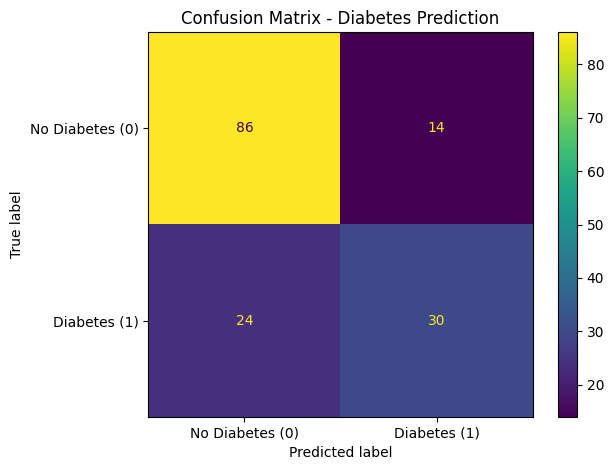

Confusion Matrix:
[[86 14]
 [24 30]]


In [34]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display it
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes (0)", "Diabetes (1)"]
)

disp.plot(values_format="d")
plt.title("Confusion Matrix - Diabetes Prediction")
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)


In [35]:

import pandas as pd

# Convert Grid Search results into a table
results = pd.DataFrame(grid_search.cv_results_)

# Select useful columns
results_table = results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "params"
    ]
].sort_values("rank_test_score").head(5)

results_table.columns = [
    "Rank",
    "Mean CV F1 Score",
    "F1 Score Std. Dev.",
    "Hyperparameters"
]

display(results_table.round(4))


,Rank,Mean CV F1 Score,F1 Score Std. Dev.,Hyperparameters
1,1,0.6744,0.0143,"{'nn__fit_kwargs': {'epochs': 20, 'batch_size'..."
2,2,0.6536,0.0003,"{'nn__fit_kwargs': {'epochs': 20, 'batch_size'..."
0,3,0.6528,0.0207,"{'nn__fit_kwargs': {'epochs': 20, 'batch_size'..."
6,4,0.6527,0.0238,"{'nn__fit_kwargs': {'epochs': 30, 'batch_size'..."
7,5,0.6426,0.0053,"{'nn__fit_kwargs': {'epochs': 30, 'batch_size'..."


## Conclusion

In this experiment, Grid Search with cross-validation was used to optimize a Keras neural network for the Pima Indians Diabetes dataset. Different configurations of learning rate, weight initialization, activation function, dropout rate, number of hidden neurons, epochs, and batch size were evaluated.

The selected model achieved a test accuracy of **75.32%** and a test F1 score of **0.6122**. The results indicate that the model performed better at identifying patients without diabetes than patients with diabetes. The confusion matrix provides further insight into correct predictions and classification errors.

Overall, the experiment demonstrates how hyperparameter tuning can help select a neural network configuration and how evaluation metrics can be used to assess classification performance.
